In [51]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k = 1.0
A, B = 2, 2
u = lambda t,x,y: -t*y
v = lambda t,x,y: 0.0
u_x = lambda t,x,y: 0.0
u_y = lambda t,x,y: -t*np.ones_like(y)
v_x = lambda t,x,y: 0.0
v_y = lambda t,x,y: 0.0
u_xx = lambda t,x,y: 0.0
u_xy = lambda t,x,y: 0.0
u_yy = lambda t,x,y: 0.0
v_xx = lambda t,x,y: 0.0
v_xy = lambda t,x,y: 0.0
v_yy = lambda t,x,y: 0.0


In [ ]:


def dphi_dt(t, x, y, phi):
    return (v_x(t, x, y)*np.sin(phi)**2
            + (u_x(t, x, y) - v_y(t, x, y))*np.sin(phi)*np.cos(phi)
            - u_y(t, x, y)*np.cos(phi)**2)

def solve_one(phi0, T, n_pts=200):
    x0, y0 = 0, 0
    def func(t, w):
        x, y, phi = w
        return [u(t, x, y) + k*np.cos(phi),
                v(t, x, y) + k*np.sin(phi),
                dphi_dt(t, x, y, phi)]
    res = solve_ivp(func, (0, T), [x0, y0, phi0],
                    t_eval=np.linspace(0, T, n_pts), atol=1e-8, rtol=1e-8)
    x, y, phi = res.y
    return x, y, phi
    
def iterate(phi_list, T_list, num=20, h_phi0=1e-7, h_T=1e-7):
    trajectories = np.empty((len(phi_list), len(T_list)), dtype=object)
    losses_total = np.empty((len(phi_list), len(T_list), num), dtype=float)
    params_total = np.empty((len(phi_list), len(T_list), num, 2), dtype=object)
    num_iters_total = np.empty((len(phi_list), len(T_list)), dtype=int)
    reached_total = np.empty((len(phi_list), len(T_list)), dtype=bool)
    """
    each (i,j) in above:
    trajectories[i,j] = trajectory of shape (num, 2) for x,y (lists)
    losses_total[i,j] = losses of shape (num,) 
    params_total[i,j] = params of shape (num, 2) for phi, T
    num_iters_total[i,j] = number of iterations
    
    """
    for i,phi in enumerate(phi_list):
        for j,T in enumerate(T_list):
            trajectory, losses, params, c, reached = deepen(num, phi, T)
            trajectories[i,j] = trajectory
            losses_total[i,j] = losses
            params_total[i,j] = params
            num_iters_total[i,j] = c
            reached_total[i,j] = reached
            #print(i, "out of", len(phi_list), j, "out of", len(T_list))

    if not reached_total.any():
        raise AssertionError("no reached")

    best_x_seq = None
    best_y_seq = None
    best_time = np.inf
    for i in range(len(phi_list)):
        for j in range(len(T_list)):
            if not reached_total[i,j]:
                continue
            num_iters = num_iters_total[i,j]
            if params_total[i,j][num_iters-1][1] < best_time or best_x_seq is None:
                best_x_seq = trajectories[i,j][num_iters-1, 0]
                best_y_seq = trajectories[i,j][num_iters-1, 1]
                best_time = params_total[i,j][num_iters-1][1]

    return best_x_seq, best_y_seq, trajectories, losses_total, params_total, num_iters_total, reached_total, best_time


def deepen(num, phi_init, T_init, pct_increase_stop=0.001, lmbda=0.5, reached_dist=0.01):

    def solve_with_S(phi0, T, n_pts=200):

        def func(t, s):
            x, y, phi = s[:3]
            S = s[3:]
            sp, cp = np.sin(phi), np.cos(phi)

            ux, uy = u_x(t, x, y), u_y(t, x, y)
            vx, vy = v_x(t, x, y), v_y(t, x, y)

            F = [u(t, x, y) + k*cp,
                v(t, x, y) + k*sp,
                dphi_dt(t, x, y, phi)]

            dF3_dx   = (v_xx(t, x, y)*sp**2
                        + (u_xx(t, x, y) - v_xy(t, x, y))*sp*cp
                        - u_xy(t, x, y)*cp**2)
            dF3_dy   = (v_xy(t, x, y)*sp**2
                        + (u_xy(t, x, y) - v_yy(t, x, y))*sp*cp
                        - u_yy(t, x, y)*cp**2)
            dF3_dphi = (2*vx*sp*cp
                        + (ux - vy)*(cp**2 - sp**2)
                        + 2*uy*sp*cp)

            M = np.array([[ux,     uy,     -k*sp],
                        [vx,     vy,      k*cp],
                        [dF3_dx, dF3_dy,  dF3_dphi]])

            return np.concatenate([F, M @ S])

        # state = (x,y,phi,S1,S2,S3)
        s0 = [0.0, 0.0, phi0, 0.0, 0.0, 1.0]       # state, then S(0) = (0, 0, 1)
        res = solve_ivp(func, (0, T), s0, t_eval=np.linspace(0, T, n_pts),
                        atol=1e-10, rtol=1e-9)
        x, y, phi, S1, S2, S3 = res.y
        return x, y, phi, S1[-1], S2[-1]

    trajectory = np.empty((num, 2), dtype=object) # x, y
    losses = np.empty(num, dtype=float)
    params = np.empty((num, 2), dtype=object)

    phi, T = phi_init, T_init
    c = 0
    pct = 1.0

    while c < num and pct >= pct_increase_stop:
        x, y, phi_seq, dx_dphi, dy_dphi = solve_with_S(phi, T)
        phi_end = phi_seq[-1]
        trajectory[c, 0] = x
        trajectory[c, 1] = y
        params[c, 0] = phi
        params[c, 1] = T
        r = np.array([x[-1] - A, y[-1] - B])
        losses[c] = np.linalg.norm(r)

        """
        for jacobian:
        second column is for T, first column is for phi
        """

        J = np.empty((2, 2), dtype=float)
        J[:,0] = [dx_dphi, dy_dphi]
        J[:,1] = np.array([u(T, x[-1], y[-1]) + k*np.cos(phi_end), v(T, x[-1], y[-1]) + k*np.sin(phi_end)])
        delta = -np.linalg.pinv(J) @ r            # Newton step in (phi, T)
        phi, T = phi + lmbda * delta[0], max(T + lmbda * delta[1], 1e-3)

        pct = np.linalg.norm(delta) / max(np.linalg.norm([phi, T]), 1e-12)
        c += 1

    reached = np.linalg.norm([x[-1] - A, y[-1] - B]) < reached_dist

    return trajectory, losses, params, c, reached

In [53]:
phi_range = np.linspace(0, np.pi, 10)
T_range = np.linspace(0.1, 10, 10)

best_x_seq, best_y_seq, trajectories, losses_total, params_total, num_iters_total, reached_total, best_time = iterate(
    phi_range, T_range, num=20
    )

print('best time:', best_time)

best time: 6.651436860391877


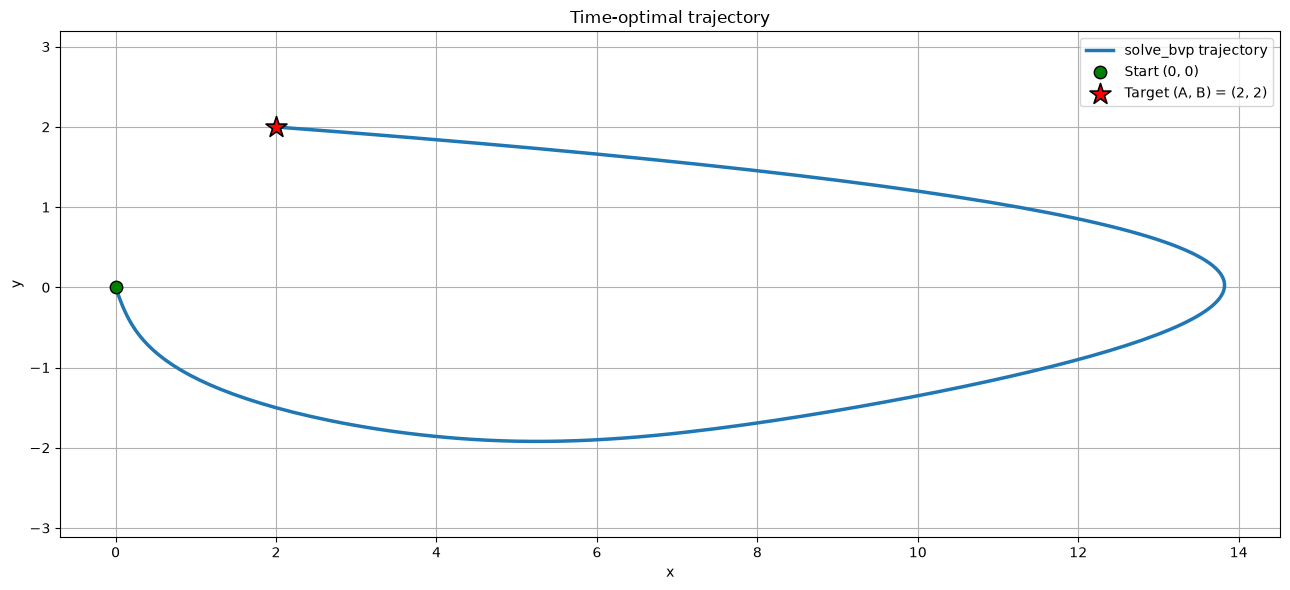

In [54]:
fig, ax = plt.subplots(figsize=(13, 6))

# Left: trajectory in the (x, y) plane
ax.plot(best_x_seq, best_y_seq, lw=2.5, label=f"solve_bvp trajectory")
ax.scatter([0], [0], color="green", s=80, marker="o",
            edgecolor="black", zorder=5, label="Start (0, 0)")
ax.scatter([A], [B], color="red", s=250, marker="*",
            edgecolor="black", linewidths=1.2, zorder=6,
            label=f"Target (A, B) = ({A:g}, {B:g})")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Time-optimal trajectory")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(True)
ax.legend()

fig.tight_layout()
plt.show()